In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Create a 2D array: 4 rows (students) x 3 columns (subjects)
marks = np.array([95,89,90,100,94,95,60,64,58,55,60,58]).reshape(4,3)

print("Shape (rows, cols):", marks.shape)

# 2. Row averages (axis=1) = each student's average
student_avg = np.mean(marks, axis=1)
print("Student averages:", np.round(student_avg, 2))

# 3. Column averages (axis=0) = each subject's average
subject_avg = np.mean(marks, axis=0)
print("Subject averages:", np.round(subject_avg, 2))

# 4. Broadcasting: add 5 grace marks to every score, capped at 100
grace_marks = np.minimum(marks + 5, 100)
print("Marks after +5 grace (capped at 100):\n", grace_marks)

# 5. Weighted score using np.dot (30% Sub1, 30% Sub2, 40% Sub3)
weights = np.array([0.3, 0.3, 0.4])
weighted_scores = np.dot(grace_marks, weights)
print("Weighted scores:", np.round(weighted_scores, 2))

# 6. Measure execution speed using %timeit
%timeit np.dot(grace_marks, weights)

Shape (rows, cols): (4, 3)
Student averages: [91.33 96.33 60.67 57.67]
Subject averages: [77.5  76.75 75.25]
Marks after +5 grace (capped at 100):
 [[100  94  95]
 [100  99 100]
 [ 65  69  63]
 [ 60  65  63]]
Weighted scores: [96.2 99.7 65.4 62.7]
1.63 μs ± 23.9 ns per loop (mean ± std. dev. of 7 runs, 1,000,000 loops each)


In [15]:
# Set up folder paths
BASE_DIR = Path("..").resolve()
DATA_DIR = BASE_DIR / "data"
REPORTS_DIR = BASE_DIR / "reports"
REPORTS_DIR.mkdir(exist_ok=True)

# Load your employees.csv
df = pd.read_csv(DATA_DIR / "employees.csv")

# Inspect column types and summary statistics
print("--- INFO ---")
print(df.info())
print("\n--- DESCRIBE ---")
print(df.describe())

# Select by label (loc) and by index position (iloc)
print("\nFirst 3 employees (name & salary):")
print(df.loc[0:2, ["name", "salary"]])

print("\nValue at row 1, column 2:", df.iloc[1, 2])

# Filter: IT employees earning more than 60,000
it_high = df[(df["department"] == "IT") & (df["salary"] > 60000)]
print("\nIT employees with salary > 60,000:")
print(it_high)

--- INFO ---
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   id          8 non-null      int64
 1   name        8 non-null      str  
 2   department  8 non-null      str  
 3   salary      8 non-null      int64
 4   city        8 non-null      str  
dtypes: int64(2), str(3)
memory usage: 452.0 bytes
None

--- DESCRIBE ---
            id        salary
count  8.00000      8.000000
mean   4.50000  58500.000000
std    2.44949  18913.336187
min    1.00000  30000.000000
25%    2.75000  47250.000000
50%    4.50000  56000.000000
75%    6.25000  69750.000000
max    8.00000  90000.000000

First 3 employees (name & salary):
    name  salary
0   Arun   30000
1  Priya   45000
2  Rahul   60000

Value at row 1, column 2: HR

IT employees with salary > 60,000:
   id    name department  salary     city
3   4   Divya         IT   75000  Chennai
6   7  Suresh         IT   68000  Ch

In [16]:
df_dirty = pd.read_csv(DATA_DIR / "employees_dirty.csv")
print("Before cleaning — rows:", len(df_dirty), "| missing salaries:", df_dirty["salary"].isna().sum())

# 1. Remove duplicate rows
df_clean = df_dirty.drop_duplicates().copy()

# 2. Fill missing salaries with the median salary
median_sal = df_clean["salary"].median()
df_clean["salary"] = df_clean["salary"].fillna(median_sal)

# 3. Convert id and salary to clean integer types
df_clean["id"] = df_clean["id"].astype(int)
df_clean["salary"] = df_clean["salary"].astype(int)

print("After cleaning — rows:", len(df_clean), "| missing salaries:", df_clean["salary"].isna().sum())
print(df_clean)

Before cleaning — rows: 9 | missing salaries: 2
After cleaning — rows: 8 | missing salaries: 0
   id     name department  salary       city
0   1     Arun      Sales   30000    Chennai
1   2    Priya         HR   64000    Chennai
2   3    Rahul         IT   60000  Bangalore
3   4    Divya         IT   75000    Chennai
4   5  Karthik    Finance   90000     Mumbai
5   6    Meena      Sales   64000  Bangalore
6   7   Suresh         IT   68000    Chennai
7   8   Anitha         HR   48000     Mumbai


In [17]:
#GroupBy department: count, average salary, max salary
dept_summary = (
    df.groupby("department", as_index=False)
    .agg(
        headcount=("id", "count"),
        avg_salary=("salary", "mean"),
        max_salary=("salary", "max")
    )
)
print("--- Department Summary ---")
print(dept_summary)

# Merge employees with departments.csv
depts = pd.read_csv(DATA_DIR / "departments.csv")

inner_join = pd.merge(df, depts, on="department", how="inner")
left_join = pd.merge(df, depts, on="department", how="left")
outer_join = pd.merge(df, depts, on="department", how="outer")

# Find departments with zero employees using the outer join
empty_depts = outer_join[outer_join["id"].isna()]["department"].tolist()
print("\nDepartment with no employees (from outer join):", empty_depts)

--- Department Summary ---
  department  headcount    avg_salary  max_salary
0    Finance          1  90000.000000       90000
1         HR          2  46500.000000       48000
2         IT          3  67666.666667       75000
3      Sales          2  41000.000000       52000

Department with no employees (from outer join): ['Marketing']


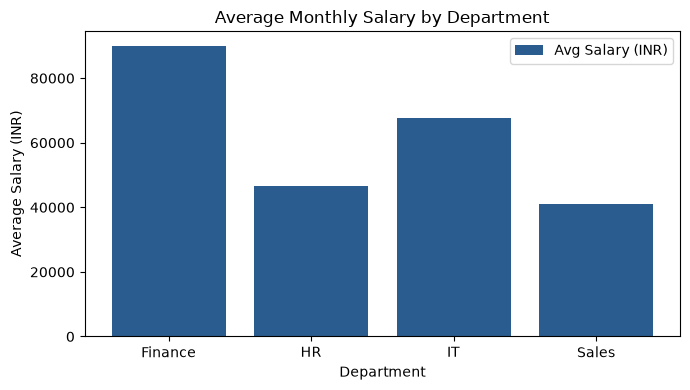

Insight 1: Finance has the highest average salary, while Sales has the lowest.


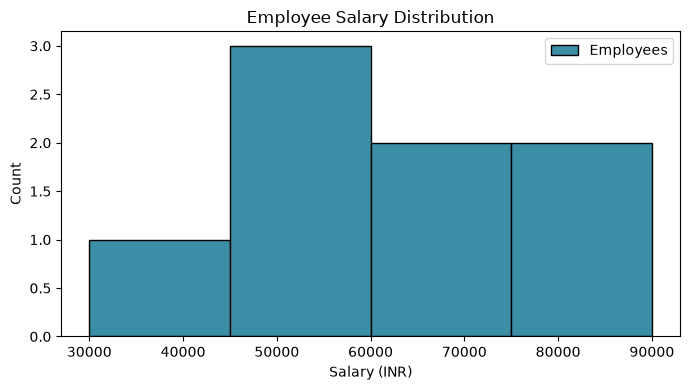

Insight 2: Most employee salaries fall between 45,000 and 75,000 INR.


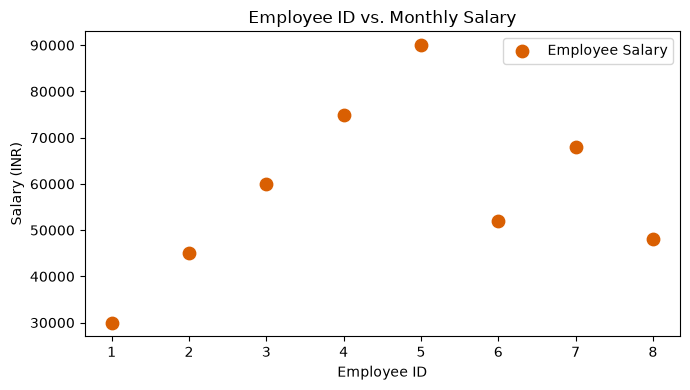

Insight 3: Salary depends on department and role rather than employee ID.


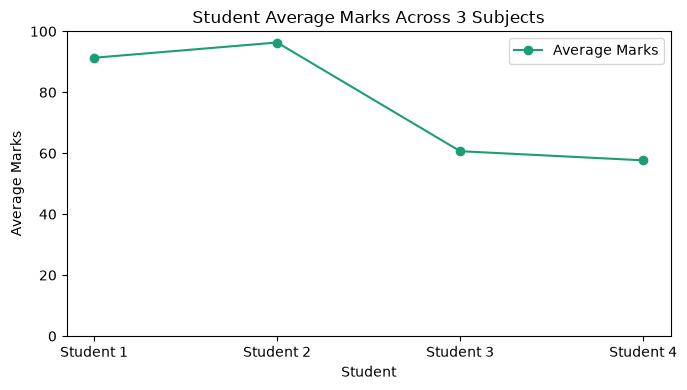

Insight 4: Student 3 scored the highest average (91.33), while Student 4 scored the lowest (57.67).


In [18]:
# Bar Chart — Average Salary by Department
plt.figure(figsize=(7, 4))
plt.bar(dept_summary["department"], dept_summary["avg_salary"], color="#2b5c8f", label="Avg Salary (INR)")
plt.title("Average Monthly Salary by Department")
plt.xlabel("Department")
plt.ylabel("Average Salary (INR)")
plt.legend()
plt.tight_layout()
plt.savefig(REPORTS_DIR / "chart1_dept_avg_salary.png")
plt.show()
print("Insight 1: Finance has the highest average salary, while Sales has the lowest.")

# Histogram — Employee Salary Distribution
plt.figure(figsize=(7, 4))
plt.hist(df["salary"], bins=4, color="#3b8ea5", edgecolor="black", label="Employees")
plt.title("Employee Salary Distribution")
plt.xlabel("Salary (INR)")
plt.ylabel("Count")
plt.legend()
plt.tight_layout()
plt.savefig(REPORTS_DIR / "chart2_salary_distribution.png")
plt.show()
print("Insight 2: Most employee salaries fall between 45,000 and 75,000 INR.")

# Scatter Plot — Employee ID vs. Salary
plt.figure(figsize=(7, 4))
plt.scatter(df["id"], df["salary"], color="#d95f02", s=80, label="Employee Salary")
plt.title("Employee ID vs. Monthly Salary")
plt.xlabel("Employee ID")
plt.ylabel("Salary (INR)")
plt.legend()
plt.tight_layout()
plt.savefig(REPORTS_DIR / "chart3_id_vs_salary.png")
plt.show()
print("Insight 3: Salary depends on department and role rather than employee ID.")

# Line Chart — Student Average Marks
students = ["Student 1", "Student 2", "Student 3", "Student 4"]
plt.figure(figsize=(7, 4))
plt.plot(students, student_avg, marker="o", color="#1b9e77", label="Average Marks")
plt.title("Student Average Marks Across 3 Subjects")
plt.xlabel("Student")
plt.ylabel("Average Marks")
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()
plt.savefig(REPORTS_DIR / "chart4_student_averages.png")
plt.show()
print("Insight 4: Student 3 scored the highest average (91.33), while Student 4 scored the lowest (57.67).")